# Expected evidence: where the Bayes factor comes from

The noiseless counterpart of the nested-sampling retrievals. The point-source model fitted to the noiseless hyperillumination truth leaves a whitened residual (each bin divided by $\sigma_{\rm bin}$, each detector's baseline removed)
$$r_\perp = \frac{h - m_{\rm ps}(\hat A_B) - \hat c}{\sigma_{\rm bin}}, \qquad \lVert r_\perp\rVert^2 = \chi^2_{\min}.$$
Both models have the same parameters and priors, so for data $d = h + \sigma z$
$$\ln B({\rm ext\ vs\ ps}) \approx \tfrac12\chi^2_{\min} + \zeta\sqrt{\chi^2_{\min}}, \qquad \zeta = \hat r_\perp\cdot z \sim N(0, 1):$$
$\langle\ln B\rangle = \chi^2_{\min}/2$ with a scatter of $\sqrt{\chi^2_{\min}}$, both from one noiseless fit. Against the fit with redistribution $\chi^2/2$ is only the likelihood part; the $F$ prior adds an Occam term of about 3–5 nats (prior $F \in [0, 0.5]$). `retrievals/03_retrieval_series.ipynb` tests the prediction on the stored retrievals.

In [1]:
import numpy as np
import pandas as pd
import contextlib, io
import matplotlib.pyplot as plt
from IPython.display import display
with contextlib.redirect_stdout(io.StringIO()):          # mute "no spidermanrc file detected"
    import fspiderman as sp
from hyperphase.defaults import DEFAULT_A, DEFAULT_A_B, DEFAULT_N_BINS, DEFAULT_N_LA, DEFAULT_N_LO, DEFAULT_N_ORBITS, DEFAULT_U, DEFAULT_U_BOL
from hyperphase.model import ConstantBandAlbedo, FittingConfig
from hyperphase.bands import filter_lambda, filter_loc, JWST_BANDS
from hyperphase.bias.detectors import detectors, instrument_key, retrieval_cfg
from hyperphase.bias.evidence import evidence_budget, evidence_probability, evidence_table
from hyperphase.plotting.bias import plot_evidence_bins
from hyperphase.plotting.style import AXIS, C_HI, C_REDIST, INK, instrument_label, MUTED, set_plot_style
from hyperphase.targets import hi_planets_by_name
from hyperphase.paper import JWST_RETRIEVALS, PAPER_PLANETS

set_plot_style()

In [2]:
# Baseline settings (hyperphase/defaults.py)
A_B_true = DEFAULT_A_B                    # injected Bond albedo of the hyperillumination truth
A_model = ConstantBandAlbedo(DEFAULT_A)   # band-integrated albedo A of the reflected light, independent of A_B
u, u_bol = DEFAULT_U, DEFAULT_U_BOL
n_orbits, n_bins = DEFAULT_N_ORBITS, DEFAULT_N_BINS
kw = dict(n_lo=DEFAULT_N_LO, n_la=DEFAULT_N_LA)

# The retrieval modes: every band singly plus the joint NIRSpec fit (a tuple = one joint fit: shared A_B / F, a baseline per detector)
LRS, JOINT = "MIRI/LRS", tuple(JWST_BANDS[:2])
PRIMARY = {"joint NIRSpec": JOINT, "MIRI/LRS": LRS}          # the paper's primary modes, by label, in wavelength order
reference_planets = ("TOI-2431 b", "K2-141 b")               # the planets of the per-bin figures and of the detection probabilities

# Template cfg: the band, the planet and the noise are replaced per fit (retrieval_cfg / instrument_retrievals); sigma_1min = 100 only serves rows without a noise level
l1, l2 = filter_lambda(LRS)
cfg = FittingConfig(planet=hi_planets_by_name(reference_planets[0]), filter_path=filter_loc(LRS), l1=l1, l2=l2, A_=A_model,
                    sigma_1min=100., n_orbits=n_orbits, n_bins=n_bins, reflected=True, u_bol=u_bol, u=u)

## 1. Per-bin evidence

The noiseless $A_B$-only fit of each reference planet in the two primary modes, one column per detector. Top: the residual (truth minus fit, baseline removed) against $\pm\sigma_{\rm bin}$; bottom: $r_\perp^2$ per bin, which sums to $\chi^2_{\min} = 2\langle\ln B\rangle$. Shaded: transit (grey), occultation (light orange), within 0.1 in phase of a quadrature (hatched). The residual has the shape $-\cos 4\pi\phi$ plus a flat in-occultation level; the tables give the share of $\chi^2_{\min}$ per window.

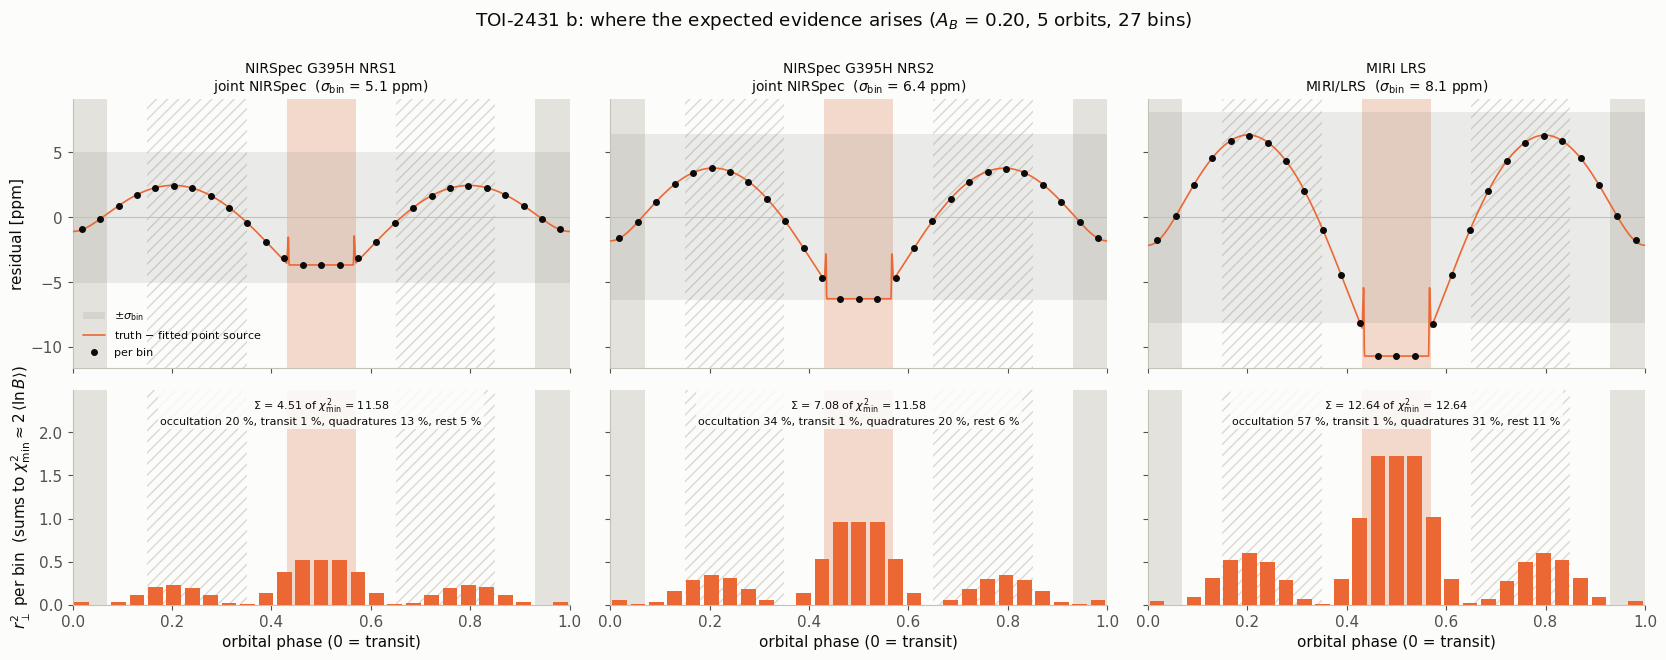

TOI-2431 b, joint NIRSpec: A_B,fit = 0.1575 (bias -0.0425),  chi2_min = 11.584  ->  <ln B> = 5.79 +- 3.40
          detector  chi2  occultation  transit  quadratures  rest  occultation [%]  transit [%]  quadratures [%]  rest [%]  share [%]
NIRSpec G395H NRS1  4.51         2.34   0.0664         1.52 0.583             20.2        0.573             13.1      5.03       38.9
NIRSpec G395H NRS2  7.08         3.94    0.124         2.34 0.664               34         1.07             20.2      5.74       61.1
               all  11.6         6.28    0.191         3.86  1.25             54.3         1.65             33.3      10.8        100 

TOI-2431 b, MIRI/LRS: A_B,fit = 0.1402 (bias -0.0598),  chi2_min = 12.635  ->  <ln B> = 6.32 +- 3.55
detector  chi2  occultation  transit  quadratures  rest  occultation [%]  transit [%]  quadratures [%]  rest [%]  share [%]
MIRI LRS  12.6         7.18   0.0945         3.92  1.44             56.9        0.748               31      11.4        100 



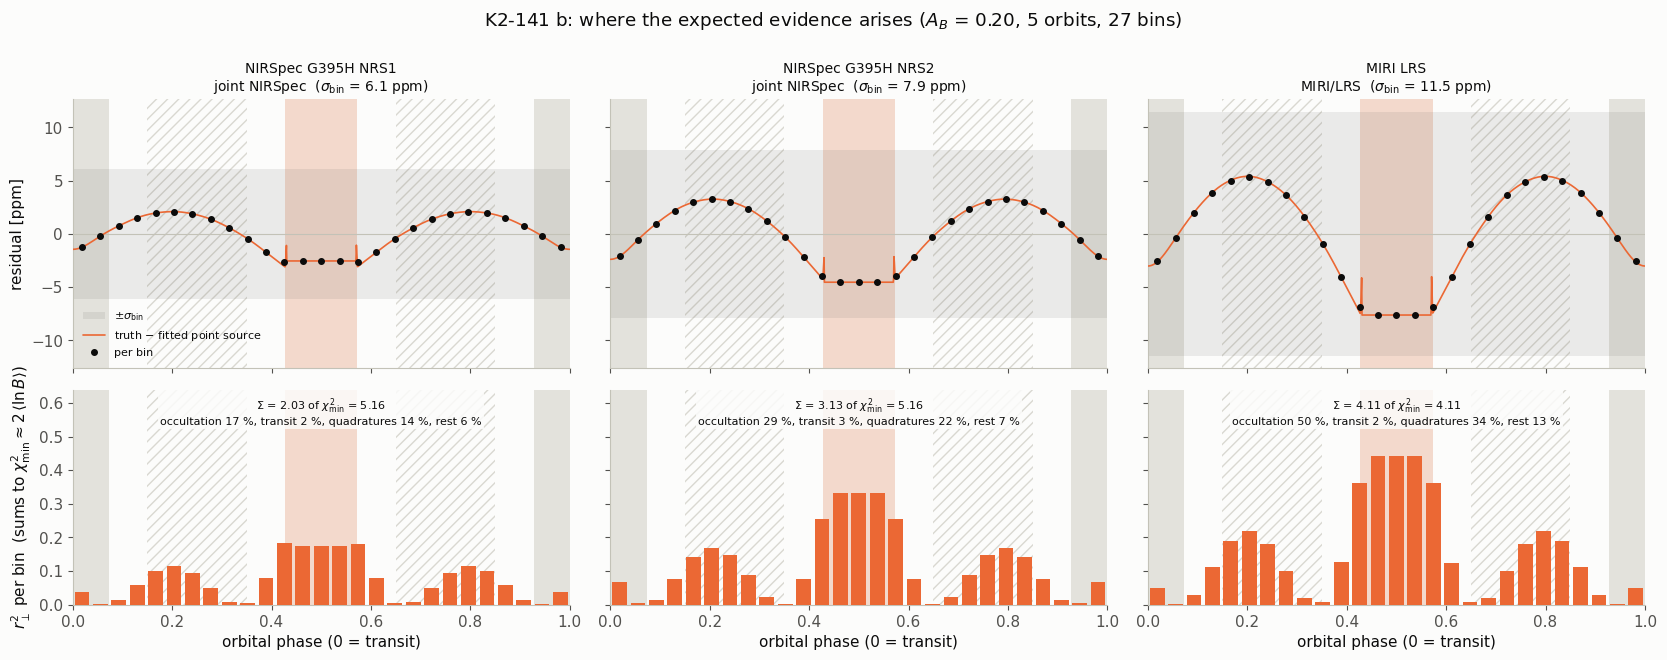

K2-141 b, joint NIRSpec: A_B,fit = 0.1576 (bias -0.0424),  chi2_min = 5.157  ->  <ln B> = 2.58 +- 2.27
          detector  chi2  occultation  transit  quadratures  rest  occultation [%]  transit [%]  quadratures [%]  rest [%]  share [%]
NIRSpec G395H NRS1  2.03        0.886   0.0808        0.738 0.322             17.2         1.57             14.3      6.24       39.3
NIRSpec G395H NRS2  3.13         1.51    0.145         1.14 0.339             29.3         2.81             22.1      6.57       60.7
               all  5.16          2.4    0.226         1.88  0.66             46.4         4.37             36.4      12.8        100 

K2-141 b, MIRI/LRS: A_B,fit = 0.1363 (bias -0.0637),  chi2_min = 4.114  ->  <ln B> = 2.06 +- 2.03
detector  chi2  occultation  transit  quadratures  rest  occultation [%]  transit [%]  quadratures [%]  rest [%]  share [%]
MIRI LRS  4.11         2.05      0.1         1.41 0.551             49.8         2.43             34.4      13.4        100 



In [3]:
EV = {}   # {planet: {mode label: evidence_residual}}
for name in reference_planets:
    pl = hi_planets_by_name(name)
    cases = {label: retrieval_cfg(cfg, pl, ins) for label, ins in PRIMARY.items()}
    fig, axes, EV[name] = plot_evidence_bins(cases, A_B_true, **kw)
    plt.show()
    for label, c in cases.items():
        ev = EV[name][label]
        print(f"{name}, {label}: A_B,fit = {ev['A_B_fit']:.4f} (bias {ev['A_B_fit'] - A_B_true:+.4f}),  chi2_min = {ev['chi2']:.3f}  ->  <ln B> = {ev['chi2'] / 2:.2f} +- {np.sqrt(ev['chi2']):.2f}")
        print(evidence_budget(ev, c, labels=[instrument_label(d, oneline=True) for d in detectors(PRIMARY[label])]).to_string(index=False, float_format=lambda v: f"{v:.3g}"), "\n")

## 2. $\langle\ln B\rangle$ for every planet and mode

`evidence_table`: every paper planet at its own geometry and noise in every mode of `JWST_RETRIEVALS`, fitted without (`naive`) and with redistribution (`naive_redist`). For `naive`: `lnB_mean` $= \chi^2_{\min}/2$, `lnB_sd` $= \sqrt{\chi^2_{\min}}$ and $P(\ln B > x)$; for `naive_redist`: `half_chi2` (the likelihood part only) and `z_F` $= \sqrt{\Delta\chi^2_F}$. Rows without a noise level keep their fitted values. The thresholds 2.5 and 5 are moderate and strong evidence (Trotta 2008).

In [4]:
tab = evidence_table(cfg, PAPER_PLANETS, JWST_RETRIEVALS, A_B_true, **kw)
tab["mode"] = tab["instrument"].map(lambda ins: instrument_label(ins, oneline=True))
fmt = lambda v: f"{v:.3g}"
pivot = lambda col, fit: tab[tab.fit == fit].pivot(index="planet", columns="mode", values=col).reindex(index=list(PAPER_PLANETS), columns=list(dict.fromkeys(tab["mode"])))

print(f"<ln B> = chi2_min / 2, A_B-only fit ({n_orbits} orbits, A_B = {A_B_true:g})")
display(pivot("lnB_mean", "naive").style.format(fmt, na_rep="-"))
print("scatter of ln B over noise realisations, sqrt(chi2_min)")
display(pivot("lnB_sd", "naive").style.format(fmt, na_rep="-"))
print("chi2 / 2 of the fit with redistribution: the likelihood part of ln B(ext vs ps+F) only, no Occam term")
display(pivot("half_chi2", "naive_redist").style.format(fmt, na_rep="-"))

no noise level, so fitted without one and no Fisher sigma: MIRI/F1280W, MIRI/F1500W, MIRI/F1800W for TOI-2260 b, K2-141 b, K2-131 b, TOI-561 b, Kepler-78 b, TOI-1444 b, TOI-1798.02, HD 80653 b; JWST_NIRSpec.G395H_NRS1, JWST_NIRSpec.G395H_NRS2, MIRI/F1280W, MIRI/F1500W, MIRI/F1800W (joint fit JWST_NIRSpec.G395H_NRS1+JWST_NIRSpec.G395H_NRS2 left out) for 55 Cnc e
<ln B> = chi2_min / 2, A_B-only fit (5 orbits, A_B = 0.2)


mode,NIRSpec G395H NRS1,NIRSpec G395H NRS2,NIRSpec G395H NRS1 + NRS2,MIRI LRS,MIRI F1280W,MIRI F1500W,MIRI F1800W
planet,,,,,,,
TOI-2431 b,2.25,3.53,5.79,6.32,0.888,0.9,0.458
TOI-2260 b,0.781,1.02,1.81,0.983,-,-,-
K2-141 b,1.01,1.56,2.58,2.06,-,-,-
K2-131 b,0.177,0.28,0.459,0.186,-,-,-
TOI-561 b,0.325,0.482,0.81,0.604,-,-,-
Kepler-78 b,0.0575,0.0917,0.149,0.0793,-,-,-
TOI-1444 b,0.133,0.201,0.334,0.199,-,-,-
TOI-1798.02,0.0946,0.16,0.255,0.17,-,-,-
HD 80653 b,0.22,0.319,0.539,0.431,-,-,-


scatter of ln B over noise realisations, sqrt(chi2_min)


mode,NIRSpec G395H NRS1,NIRSpec G395H NRS2,NIRSpec G395H NRS1 + NRS2,MIRI LRS,MIRI F1280W,MIRI F1500W,MIRI F1800W
planet,,,,,,,
TOI-2431 b,2.12,2.66,3.4,3.55,1.33,1.34,0.958
TOI-2260 b,1.25,1.43,1.9,1.4,-,-,-
K2-141 b,1.42,1.77,2.27,2.03,-,-,-
K2-131 b,0.595,0.748,0.958,0.611,-,-,-
TOI-561 b,0.807,0.982,1.27,1.1,-,-,-
Kepler-78 b,0.339,0.428,0.547,0.398,-,-,-
TOI-1444 b,0.516,0.633,0.818,0.631,-,-,-
TOI-1798.02,0.435,0.566,0.715,0.584,-,-,-
HD 80653 b,0.663,0.799,1.04,0.928,-,-,-


chi2 / 2 of the fit with redistribution: the likelihood part of ln B(ext vs ps+F) only, no Occam term


mode,NIRSpec G395H NRS1,NIRSpec G395H NRS2,NIRSpec G395H NRS1 + NRS2,MIRI LRS,MIRI F1280W,MIRI F1500W,MIRI F1800W
planet,,,,,,,
TOI-2431 b,0.858,1.36,2.73,2.31,0.302,0.301,0.15
TOI-2260 b,0.341,0.442,0.921,0.406,-,-,-
K2-141 b,0.483,0.748,1.46,0.937,-,-,-
K2-131 b,0.0977,0.158,0.299,0.103,-,-,-
TOI-561 b,0.185,0.277,0.535,0.337,-,-,-
Kepler-78 b,0.0299,0.0495,0.097,0.0425,-,-,-
TOI-1444 b,0.0755,0.116,0.221,0.112,-,-,-
TOI-1798.02,0.0545,0.0962,0.177,0.102,-,-,-
HD 80653 b,0.128,0.19,0.372,0.253,-,-,-


## 3. Detection probabilities

$P(\ln B > x) = 1 - \Phi[(x - \chi^2_{\min}/2)/\sqrt{\chi^2_{\min}}]$ (`evidence_probability`). Since $\chi^2_{\min} \propto n_{\rm orbits}$, another observing time needs no refit: `N_ORBITS_ALT` adds rows (2 orbits is roughly one JWST GO 8864 visit of TOI-2431 b), and the figure gives the probabilities against the number of orbits.

    planet                      mode  n_orbits  t_obs_h  lnB_mean  lnB_sd  P(ln B > 2.5)  P(ln B > 5)
TOI-2431 b NIRSpec G395H NRS1 + NRS2         5     26.9      5.79     3.4          0.833        0.592
TOI-2431 b NIRSpec G395H NRS1 + NRS2         2     10.8      2.32    2.15          0.466        0.106
TOI-2431 b                  MIRI LRS         5     26.9      6.32    3.55          0.859        0.645
TOI-2431 b                  MIRI LRS         2     10.8      2.53    2.25          0.505        0.136
  K2-141 b NIRSpec G395H NRS1 + NRS2         5     33.6      2.58    2.27          0.514        0.143
  K2-141 b NIRSpec G395H NRS1 + NRS2         2     13.5      1.03    1.44          0.153      0.00286
  K2-141 b                  MIRI LRS         5     33.6      2.06    2.03          0.414       0.0734
  K2-141 b                  MIRI LRS         2     13.5     0.823    1.28         0.0955     0.000565


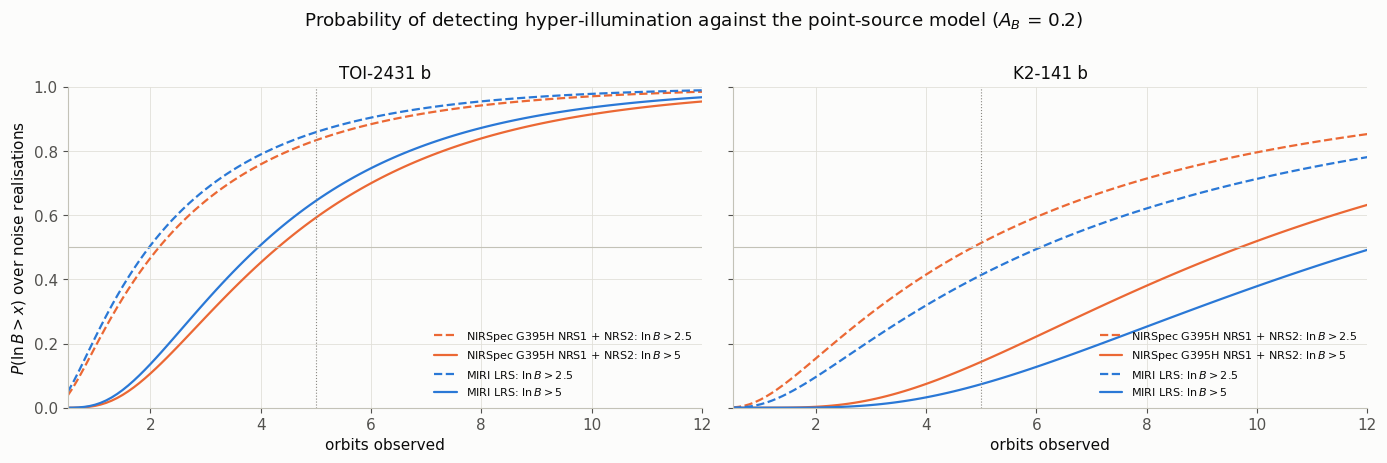

In [5]:
N_ORBITS_ALT = (2,)                       # other numbers of orbits, next to n_orbits
THRESHOLDS = tab.attrs["thresholds"]      # ln B thresholds of the table (2.5, 5)

ref = tab[(tab.fit == "naive") & tab["planet"].isin(reference_planets) & tab["instrument"].isin([instrument_key(ins) for ins in PRIMARY.values()])]
rows = []
for _, r in ref.iterrows():
    for n in (n_orbits, *N_ORBITS_ALT):
        s = n / n_orbits
        rows.append(dict(planet=r["planet"], mode=r["mode"], n_orbits=n, t_obs_h=n * 24. * hi_planets_by_name(r["planet"]).period, lnB_mean=0.5 * s * r["chi2"], lnB_sd=np.sqrt(s * r["chi2"]),
                         **{f"P(ln B > {x:g})": float(evidence_probability(r["chi2"], x, s)) for x in THRESHOLDS}))
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3g}"))

n_grid = np.linspace(0.5, 12., 116)
fig, axs = plt.subplots(1, len(reference_planets), figsize=(7. * len(reference_planets), 4.6), sharey=True, squeeze=False)
for ax, name in zip(axs.ravel(), reference_planets):
    for (_, r), col in zip(ref[ref.planet == name].iterrows(), (C_HI, C_REDIST)):
        for x, ls in zip(THRESHOLDS, ("--", "-")):
            ax.plot(n_grid, evidence_probability(r["chi2"], x, n_grid / n_orbits), color=col, ls=ls, lw=1.6, label=rf"{r['mode']}: $\ln B > {x:g}$")
    ax.axhline(0.5, color=AXIS, lw=.8)
    ax.axvline(n_orbits, color=MUTED, lw=.8, ls=":")
    ax.set_xlabel("orbits observed"); ax.set_title(name); ax.set_ylim(0., 1.); ax.set_xlim(n_grid[0], n_grid[-1])
    ax.legend(fontsize=8, loc="lower right")
axs[0, 0].set_ylabel(r"$P(\ln B > x)$ over noise realisations")
fig.suptitle(rf"Probability of detecting hyper-illumination against the point-source model ($A_B$ = {A_B_true:g})", y=1.0)
fig.tight_layout()
plt.show()

## 4. The bias–evidence plane

Every planet and mode of section 2: the bias significance $(\Delta A_B/\sigma_{A_B})^2$ against $\chi^2_{\min}/2$ ($\langle\ln B\rangle$ for the $A_B$-only fit, circles; only the likelihood part for the fit with redistribution, squares). Both axes scale with $n_{\rm orbits}/\sigma_{1\rm min}^2$, so more observing time moves a point along a line of slope 1 (dotted: `MARK_CASE`). Below the solid line the evidence becomes strong before the bias reaches $2\sigma$, above it the bias comes first. The printed lists name the planets in the off-diagonal quadrants.

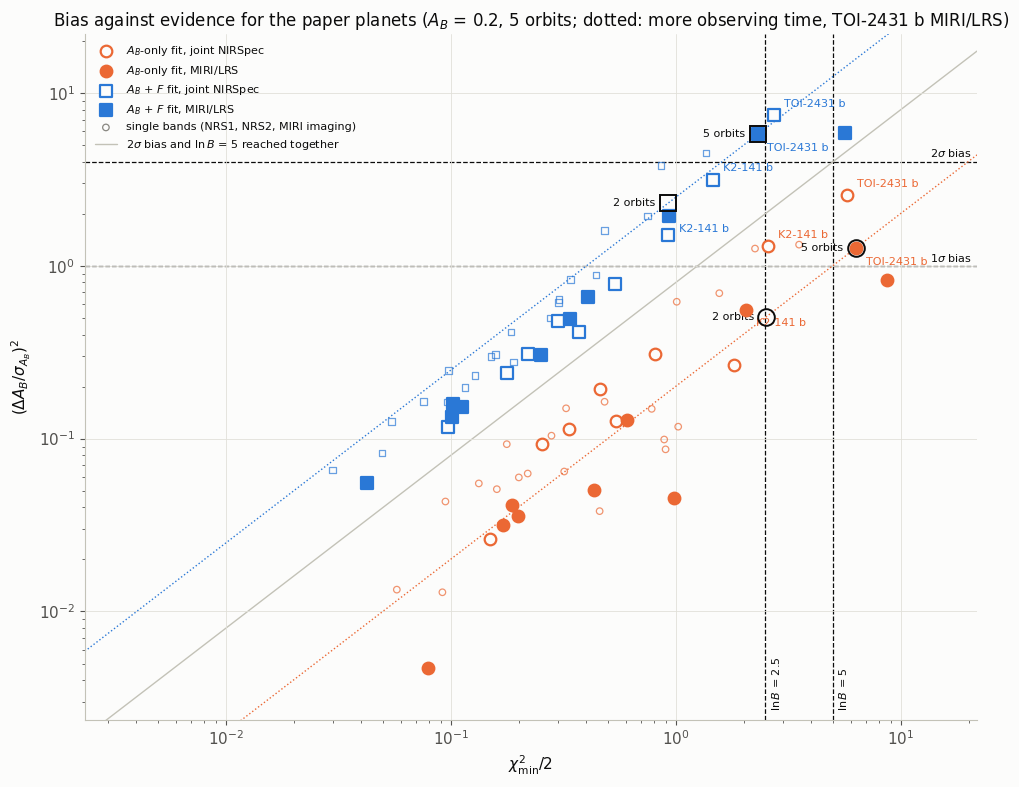

A_B-only fit: 0 of 40 points above the solid line (2 sigma bias before ln B = 5); (dA_B/sigma)^2 / (chi2_min/2) = 0.046 to 0.61
   bias >= 1 sigma but chi2_min / 2 < 2.5: TOI-2431 b [NIRSpec G395H NRS1]
   chi2_min / 2 >= 2.5 but bias < 1 sigma: 55 Cnc e [MIRI LRS]
   both: TOI-2431 b [NIRSpec G395H NRS2], TOI-2431 b [NIRSpec G395H NRS1 + NRS2], TOI-2431 b [MIRI LRS], K2-141 b [NIRSpec G395H NRS1 + NRS2]
A_B + F fit (x: likelihood part only): 40 of 40 points above the solid line (2 sigma bias before ln B = 5); (dA_B/sigma)^2 / (chi2_min/2) = 1 to 4.4
   bias >= 1 sigma but chi2_min / 2 < 2.5: TOI-2431 b [NIRSpec G395H NRS1], TOI-2431 b [NIRSpec G395H NRS2], TOI-2431 b [MIRI LRS], TOI-2260 b [NIRSpec G395H NRS1 + NRS2], K2-141 b [NIRSpec G395H NRS1], K2-141 b [NIRSpec G395H NRS2], K2-141 b [NIRSpec G395H NRS1 + NRS2], K2-141 b [MIRI LRS]
   chi2_min / 2 >= 2.5 but bias < 1 sigma: -
   both: TOI-2431 b [NIRSpec G395H NRS1 + NRS2], 55 Cnc e [MIRI LRS]


In [6]:
MARK_CASE = ("TOI-2431 b", instrument_key(LRS))   # the planet and mode whose track in observing time is drawn
N_ORBITS_MARK = (n_orbits, 2)                     # positions marked on it
LNB_LINES, SIGMA_LINES = (2.5, 5.), (1., 2.)
PAIR = (SIGMA_LINES[1], LNB_LINES[1])             # the solid line pairs a 2 sigma bias with ln B = 5 and runs through the crossing of those two dashed lines
PAIR_SLOPE = PAIR[0] ** 2 / PAIR[1]               # (dA_B/sigma)^2 = PAIR_SLOPE * chi2_min/2; the tracks in observing time run parallel to it, so below it ln B = 5 comes before a 2 sigma bias

pts = tab[tab["sigma_A_B"].notna() & tab["chi2"].notna()].assign(bias2=lambda t: t["bias_sigma"] ** 2)
MODE_MARK = {instrument_key(JOINT): ("joint NIRSpec", 1.0), instrument_key(LRS): ("MIRI/LRS", 1.0)}   # primary modes: full size; the other bands smaller and paler
FIT_STYLE = {"naive": ("o", C_HI, r"$A_B$-only fit  ($x = \langle\ln B\rangle$)"), "naive_redist": ("s", C_REDIST, r"$A_B$ + $F$ fit  ($x$ = likelihood part of $\ln B$ only)")}

fig, ax = plt.subplots(figsize=(10., 8.))
for fit, (mk, col, lab) in FIT_STYLE.items():
    t = pts[pts.fit == fit]
    prim = t["instrument"].isin(MODE_MARK)
    ax.scatter(t.loc[~prim, "half_chi2"], t.loc[~prim, "bias2"], marker=mk, s=22, facecolor="none", edgecolor=col, linewidths=.9, alpha=.7, zorder=3)
    for ins, fill in ((instrument_key(JOINT), "#fcfcfb"), (instrument_key(LRS), col)):   # legend in wavelength order
        u_ = t[t["instrument"] == ins]
        ax.scatter(u_["half_chi2"], u_["bias2"], marker=mk, s=70, facecolor=fill, edgecolor=col, linewidths=1.6, zorder=4, label=f"{lab.split('  ')[0]}, {MODE_MARK[ins][0]}")
    for _, r in t[prim & t["planet"].isin(reference_planets)].iterrows():
        ax.annotate(r["planet"], (r["half_chi2"], r["bias2"]), xytext=(7, 6) if r["instrument"] == instrument_key(JOINT) else (7, -12), textcoords="offset points", fontsize=8, color=col)   # joint NIRSpec above, MIRI/LRS below its marker
ax.scatter([], [], marker="o", s=22, facecolor="none", edgecolor=MUTED, linewidths=.9, label="single bands (NRS1, NRS2, MIRI imaging)")

for x in LNB_LINES: ax.axvline(x, color=INK, lw=.9, ls="--", zorder=1)
for z in SIGMA_LINES: ax.axhline(z ** 2, color=INK, lw=.9, ls="--", zorder=1)
ax.set_xscale("log"); ax.set_yscale("log")
lo, hi = min(pts["half_chi2"].min(), pts["bias2"].min()) / 2., max(pts["half_chi2"].max(), pts["bias2"].max()) * 2.5
ax.plot([lo, hi], [PAIR_SLOPE * lo, PAIR_SLOPE * hi], color=AXIS, lw=1., zorder=1, label=rf"{PAIR[0]:g}$\sigma$ bias and $\ln B$ = {PAIR[1]:g} reached together")   # (dA_B/sigma)^2 = PAIR_SLOPE * chi2_min / 2
for fit, (mk, col, _) in FIT_STYLE.items():   # the track of MARK_CASE in observing time, both fits
    r = pts[(pts.planet == MARK_CASE[0]) & (pts.instrument == MARK_CASE[1]) & (pts.fit == fit)]
    if not len(r): continue
    x0, y0 = float(r["half_chi2"].iloc[0]), float(r["bias2"].iloc[0])
    ax.plot([lo, hi], [lo * y0 / x0, hi * y0 / x0], color=col, lw=1., ls=":", zorder=2)
    for n in N_ORBITS_MARK:
        ax.plot(x0 * n / n_orbits, y0 * n / n_orbits, marker=mk, ms=12, mfc="none", mec=INK, mew=1.4, zorder=5)
        ax.annotate(f"{n} orbits", (x0 * n / n_orbits, y0 * n / n_orbits), xytext=(-9, 0), textcoords="offset points", fontsize=8, ha="right", va="center")
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
for x in LNB_LINES: ax.annotate(rf"$\ln B$ = {x:g}", (x, lo), xytext=(3, 6), textcoords="offset points", fontsize=8, rotation=90, va="bottom")
for z in SIGMA_LINES: ax.annotate(rf"{z:g}$\sigma$ bias", (hi, z ** 2), xytext=(-4, 3), textcoords="offset points", fontsize=8, ha="right")
ax.set_xlabel(r"$\chi^2_{\min}/2$"); ax.set_ylabel(r"$(\Delta A_B/\sigma_{A_B})^2$")
ax.legend(fontsize=8, loc="upper left")
ax.set_title(rf"Bias against evidence for the paper planets ($A_B$ = {A_B_true:g}, {n_orbits} orbits; dotted: more observing time, {MARK_CASE[0]} {MODE_MARK[MARK_CASE[1]][0]})")
fig.tight_layout()
plt.show()

name = lambda t: ", ".join(f"{r['planet']} [{r['mode']}]" for _, r in t.iterrows()) or "-"
for fit, (_, _, lab) in FIT_STYLE.items():
    t = pts[pts.fit == fit]
    y_over_x = t["bias2"] / t["half_chi2"]   # constant along the track in observing time
    print(f"{'A_B-only fit' if fit == 'naive' else 'A_B + F fit (x: likelihood part only)'}: {(y_over_x > PAIR_SLOPE).sum()} of {len(t)} points above the solid line ({PAIR[0]:g} sigma bias before ln B = {PAIR[1]:g}); (dA_B/sigma)^2 / (chi2_min/2) = {y_over_x.min():.2g} to {y_over_x.max():.2g}")
    print(f"   bias >= {SIGMA_LINES[0]:g} sigma but chi2_min / 2 < {LNB_LINES[0]:g}: {name(t[(t['bias_sigma'] >= SIGMA_LINES[0]) & (t['half_chi2'] < LNB_LINES[0])])}")
    print(f"   chi2_min / 2 >= {LNB_LINES[0]:g} but bias < {SIGMA_LINES[0]:g} sigma: {name(t[(t['bias_sigma'] < SIGMA_LINES[0]) & (t['half_chi2'] >= LNB_LINES[0])])}")
    print(f"   both: {name(t[(t['bias_sigma'] >= SIGMA_LINES[0]) & (t['half_chi2'] >= LNB_LINES[0])])}")